In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
import numpy as np
import torch
from cloudvolume import CloudVolume

cv = CloudVolume(
    "file:///volume_4/research/seongbong/align/"
    "Final_cerebellum_alignment/render_sift_new/img/img_rendered",
    mip=8,
    progress=False,
)

def read_image(x0, x1, y0, y1, z):
    return np.asarray(
        cv[x0:x1, y0:y1, z:z+1]
    )[:, :, 0, 0].T.astype(np.float32)


    
img = read_image(0, 975, 0, 900, 341)

def make_background_mask(img, atol=0.01):
    img = np.asarray(img)

    # 이미지 외곽의 intensity
    border = np.concatenate([
        img[0, :],
        img[-1, :],
        img[:, 0],
        img[:, -1]
    ])

    # 외곽에서 가장 빈번하게 나타나는 값
    values, counts = np.unique(border, return_counts=True)
    bg_value = values[np.argmax(counts)]

    # 배경값과 비슷한 픽셀
    candidate = np.isclose(
        img, bg_value,
        atol=atol,
        rtol=0
    )

    # 외곽에 연결된 영역만 선택
    seeds = np.zeros_like(candidate, dtype=bool)

    seeds[0, :] = candidate[0, :]
    seeds[-1, :] = candidate[-1, :]
    seeds[:, 0] = candidate[:, 0]
    seeds[:, -1] = candidate[:, -1]

    background_mask = ndi.binary_propagation(
        seeds,
        mask=candidate
    )

    return background_mask, bg_value


background_mask, bg_value = make_background_mask(img)

print("Background intensity:", bg_value)
print("Background ratio:", background_mask.mean())

Background intensity: 0.0
Background ratio: 0.7264820512820512


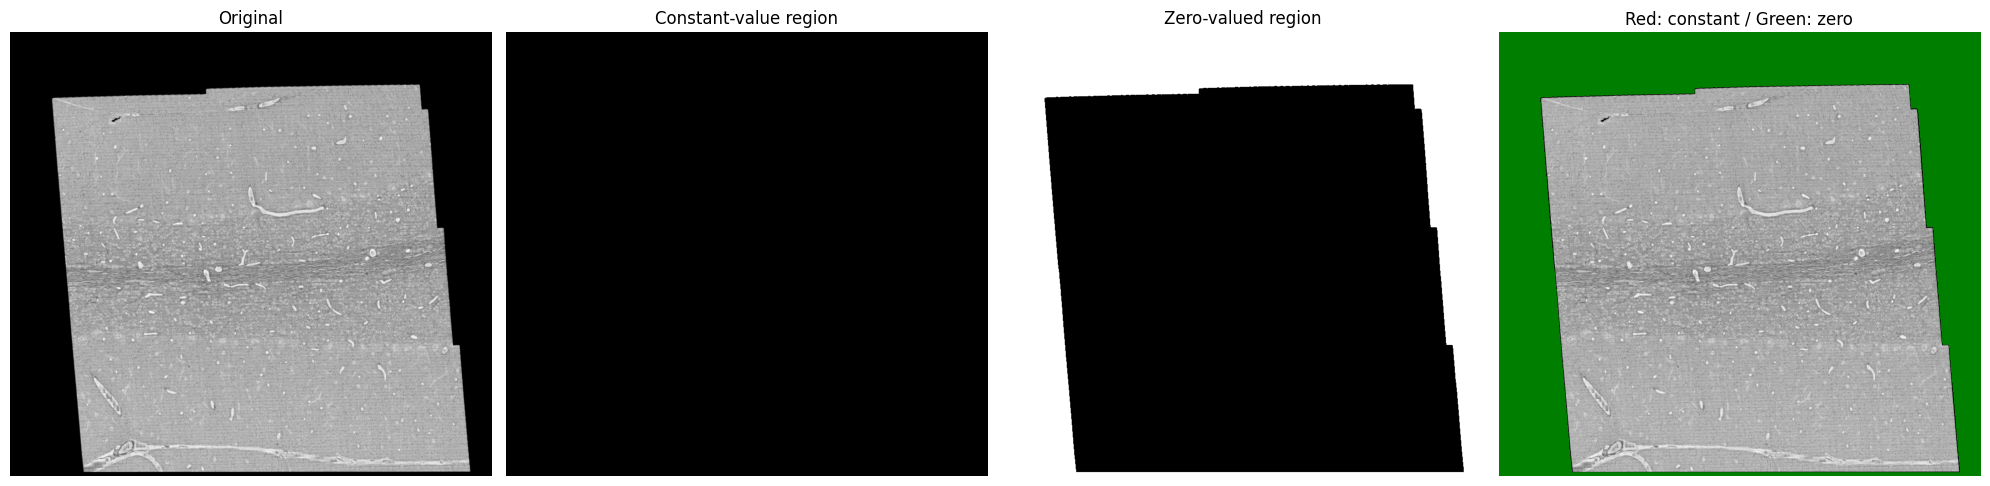

Constant region: 0.0
Zero region: 0.32045698005698003
Combined: 0.32045698005698003


In [7]:
import numpy as np
import matplotlib.pyplot as plt

img = read_image(0, 975, 0, 900, 266)

# 일정한 음수 배경
black_mask = np.isclose(
    img, -6.974372,
    atol=1e-4,
    rtol=0
)

# 정확히 0인 영역
zero_mask = (img == 0)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(img, cmap="gray")
axes[0].set_title("Original")

axes[1].imshow(black_mask, cmap="gray")
axes[1].set_title("Constant-value region")

axes[2].imshow(zero_mask, cmap="gray")
axes[2].set_title("Zero-valued region")

axes[3].imshow(img, cmap="gray")
overlay = np.zeros((*img.shape, 4), dtype=np.float32)
overlay[black_mask] = [1, 0, 0, 0.5]   # 빨간색
overlay[zero_mask] = [0, 1, 0, 0.5]    # 초록색
axes[3].imshow(overlay)
axes[3].set_title("Red: constant / Green: zero")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Constant region:", black_mask.mean())
print("Zero region:", zero_mask.mean())
print("Combined:", (black_mask | zero_mask).mean())

In [3]:
import numpy as np
from scipy.ndimage import binary_dilation

def mask_resin(img, dilation=2, atol=1e-4):
    img = np.asarray(img, dtype=np.float32)

    # 1. 가장 빈번한 intensity 추정
    values, counts = np.unique(img, return_counts=True)
    bg_value = values[np.argmax(counts)]

    # 2. Black background mask
    black_mask = np.isclose(
        img, bg_value,
        atol=atol,
        rtol=0
    )

    # 3. Zero resin mask
    zero_mask = (img == 0)

    # 4. Mask 결합 및 dilation
    invalid_mask = black_mask | zero_mask

    if dilation > 0:
        invalid_mask = binary_dilation(
            invalid_mask,
            iterations=dilation
        )

    # 5. Mask 적용
    img_masked = img.copy()
    img_masked[invalid_mask] = 0

    return img_masked, invalid_mask, bg_value

In [4]:
import numpy as np
from scipy.ndimage import binary_dilation

def mask_and_normalize(img, dilation=1):
    img = np.asarray(img, dtype=np.float32)

    # 1. Zero 및 비정상 픽셀 제외
    invalid_mask = (img == 0) | ~np.isfinite(img)

    # 2. Mask 경계 확장
    if dilation > 0:
        invalid_mask = binary_dilation(
            invalid_mask,
            iterations=dilation
        )

    # 3. Tissue 통계 계산
    valid_mask = ~invalid_mask
    tissue = img[valid_mask]

    if tissue.size == 0:
        return np.zeros_like(img), invalid_mask, np.nan, np.nan

    mean = tissue.mean(dtype=np.float64)
    std = tissue.std(dtype=np.float64)

    if not np.isfinite(std) or std < 1e-8:
        return np.zeros_like(img), invalid_mask, mean, std

    # 4. Normalization
    img_norm = np.zeros_like(img, dtype=np.float32)
    img_norm[valid_mask] = (img[valid_mask] - mean) / std

    return img_norm, invalid_mask, mean, std




import numpy as np
from scipy.ndimage import binary_dilation

def apply_mask(img, dilation=1):
    img = np.asarray(img, dtype=np.float32)

    # 1. Invalid pixel 검출
    invalid_mask = (img == 0) | ~np.isfinite(img)

    # 2. Mask 경계 확장
    if dilation > 0:
        invalid_mask = binary_dilation(
            invalid_mask,
            iterations=dilation
        )

    # 3. Mask 적용 (재정규화 없음)
    img_masked = img.copy()
    img_masked[invalid_mask] = 0.0

    return img_masked, invalid_mask

In [8]:
import numpy as np
import pandas as pd
import copy

from cloudvolume import CloudVolume
from scipy.ndimage import binary_dilation
from tqdm.auto import tqdm


# ==========================================
# 1. Paths & parameters
# ==========================================

src_path = (
    "file:///volume_4/research/seongbong/"
    "align/Final_cerebellum_alignment/render_sift_new/img/img_rendered"
)

dst_path = (
    "file:///volume_4/research/seongbong/"
    "align/Final_cerebellum_alignment/render_sift_new_masked"
)

mip = 8
z_start, z_end = 70, 1173
dilation = 1


# ==========================================
# 2. Functions
# ==========================================

def read_image(x0, x1, y0, y1, z):
    return np.asarray(
        src_cv[x0:x1, y0:y1, z:z+1]
    )[:, :, 0, 0].T.astype(np.float32)


def apply_mask(img, dilation=1):
    img = np.asarray(img, dtype=np.float32)

    # Detect invalid pixels
    invalid_mask = (img == 0) | ~np.isfinite(img)

    # Expand invalid regions
    if dilation > 0:
        invalid_mask = binary_dilation(
            invalid_mask,
            iterations=dilation
        )

    # Preserve original normalized intensity
    img_masked = img.copy()
    img_masked[invalid_mask] = 0.0

    return img_masked, invalid_mask


# ==========================================
# 3. Source CloudVolume
# ==========================================

src_cv = CloudVolume(
    src_path,
    mip=mip,
    bounded=False,
    progress=False,
    fill_missing=True
)

print("Source shape:", src_cv.shape)
print("Resolution:", src_cv.resolution)
print("Voxel offset:", src_cv.voxel_offset)
print("Chunk size:", src_cv.chunk_size)


# ==========================================
# 4. Destination CloudVolume
# ==========================================

dst_info = copy.deepcopy(src_cv.info)

dst_info["data_type"] = "float32"
dst_info["num_channels"] = 1

dst_cv = CloudVolume(
    dst_path,
    mip=mip,
    info=dst_info,
    bounded=False,
    progress=False,
    compress=False,
    fill_missing=True
)

dst_cv.commit_info()

print("Destination:", dst_path)


# ==========================================
# 5. Apply masking and save
# ==========================================

records = []

x0, y0, z0 = map(int, src_cv.bounds.minpt)
x1, y1, z1 = map(int, src_cv.bounds.maxpt)

for z in tqdm(range(z_start, z_end)):

    # Read SIFT-aligned normalized image (y, x)
    img = read_image(x0, x1, y0, y1, z)

    # Masking only (no re-normalization)
    img_masked, invalid_mask = apply_mask(
        img,
        dilation=dilation
    )

    # Valid tissue pixels
    valid_mask = ~invalid_mask

    if np.any(valid_mask):
        tissue_mean = float(img_masked[valid_mask].mean())
        tissue_std = float(img_masked[valid_mask].std())
    else:
        tissue_mean = np.nan
        tissue_std = np.nan

    # Convert to CloudVolume format (x, y, z, c)
    data = img_masked.T[:, :, None, None].astype(np.float32)

    # Save
    dst_cv[x0:x1, y0:y1, z:z+1] = data

    # Log
    records.append({
        "z": z,
        "masked_ratio": float(invalid_mask.mean()),
        "tissue_mean": tissue_mean,
        "tissue_std": tissue_std,
    })


# ==========================================
# 6. Summary
# ==========================================

df_log = pd.DataFrame(records)

display(df_log)

Source shape: (975, 900, 1200, 1)
Resolution: [1024 1024   40]
Voxel offset: [0 0 0]
Chunk size: [512 512   1]
Destination: file:///volume_4/research/seongbong/align/Final_cerebellum_alignment/render_sift_new_masked


  0%|          | 0/682 [00:00<?, ?it/s]

,z,masked_ratio,tissue_mean,tissue_std
0,491,0.295520,143.419296,13.844563
1,492,0.291916,140.754379,12.997508
2,493,1.000000,NaN,NaN
3,494,0.290383,141.023560,13.646121
4,495,0.286301,141.309845,12.733538
...,...,...,...,...
677,1168,0.300207,136.770828,13.308050
678,1169,0.297346,132.573273,11.998488
679,1170,0.304164,136.650818,13.060769
680,1171,1.000000,NaN,NaN


In [17]:
import numpy as np
import pandas as pd
import copy

from cloudvolume import CloudVolume
from scipy.ndimage import binary_dilation
from tqdm.auto import tqdm


# ==========================================
# 1. Paths & parameters
# ==========================================

src_path = (
    "file:///volume_4/research/seongbong/"
    "align/Final_cerebellum_alignment/render_sift_new/img/img_rendered"
)

dst_path = (
    "file:///volume_4/research/seongbong/"
    "align/Final_cerebellum_alignment/render_sift_new_masked_normalized"
)

mip = 8
z_start, z_end = 70, 1173
dilation = 2


# ==========================================
# 2. Functions
# ==========================================

def read_image(x0, x1, y0, y1, z):
    return np.asarray(
        src_cv[x0:x1, y0:y1, z:z+1]
    )[:, :, 0, 0].T.astype(np.float32)


def apply_mask(img, dilation=1):
    img = np.asarray(img, dtype=np.float32)

    # Detect invalid pixels
    invalid_mask = (img == 0) | ~np.isfinite(img)

    # Expand invalid regions
    if dilation > 0:
        invalid_mask = binary_dilation(
            invalid_mask,
            iterations=dilation
        )

    # Preserve original normalized intensity
    img_masked = img.copy()
    img_masked[invalid_mask] = 0.0

    return img_masked, invalid_mask


# ==========================================
# 3. Source CloudVolume
# ==========================================

src_cv = CloudVolume(
    src_path,
    mip=mip,
    bounded=False,
    progress=False,
    fill_missing=True
)

print("Source shape:", src_cv.shape)
print("Resolution:", src_cv.resolution)
print("Voxel offset:", src_cv.voxel_offset)
print("Chunk size:", src_cv.chunk_size)


# ==========================================
# 4. Destination CloudVolume
# ==========================================

dst_info = copy.deepcopy(src_cv.info)

dst_info["data_type"] = "float32"
dst_info["num_channels"] = 1

dst_cv = CloudVolume(
    dst_path,
    mip=mip,
    info=dst_info,
    bounded=False,
    progress=False,
    compress=False,
    fill_missing=True
)

dst_cv.commit_info()

print("Destination:", dst_path)


# ==========================================
# 5. Apply masking and save
# ==========================================

records = []

x0, y0, z0 = map(int, src_cv.bounds.minpt)
x1, y1, z1 = map(int, src_cv.bounds.maxpt)

for z in tqdm(range(z_start, z_end)):

    # Read SIFT-aligned normalized image (y, x)
    img = read_image(x0, x1, y0, y1, z)

    # Masking + normalization
    img_norm, invalid_mask, mean, std = mask_and_normalize(
        img,
        dilation=dilation
    )

    # Valid tissue pixels
    valid_mask = ~invalid_mask
    
    if np.any(valid_mask):
        tissue_mean = float(img_norm[valid_mask].mean())
        tissue_std = float(img_norm[valid_mask].std())
    else:
        tissue_mean = np.nan
        tissue_std = np.nan
    
    # Convert to CloudVolume format
    data = img_norm.T[:, :, None, None].astype(np.float32)
    
    # Save
    dst_cv[x0:x1, y0:y1, z:z+1] = data
    
    # Log
    records.append({
        "z": z,
        "masked_ratio": float(invalid_mask.mean()),
        "tissue_mean_before": float(mean),
        "tissue_std_before": float(std),
        "tissue_mean_after": tissue_mean,
        "tissue_std_after": tissue_std,
    })

# ==========================================
# 6. Summary
# ==========================================

df_log = pd.DataFrame(records)

display(df_log)

Source shape: (975, 900, 1200, 1)
Resolution: [1024 1024   40]
Voxel offset: [0 0 0]
Chunk size: [512 512   1]
Destination: file:///volume_4/research/seongbong/align/Final_cerebellum_alignment/render_sift_new_masked_normalized


  0%|          | 0/1103 [00:00<?, ?it/s]

,z,masked_ratio,tissue_mean_before,tissue_std_before,tissue_mean_after,tissue_std_after
0,70,0.281407,154.364383,17.423798,1.715197e-07,1.0
1,71,0.287315,150.956825,18.462426,3.767235e-07,1.0
2,72,0.295606,147.033171,17.177961,-9.854796e-08,1.0
3,73,1.000000,NaN,NaN,NaN,NaN
4,74,0.318250,148.462272,15.792413,4.721727e-07,1.0
...,...,...,...,...,...,...
1098,1168,0.303875,136.947151,12.921054,5.371613e-07,1.0
1099,1169,0.302284,132.833614,11.344601,-3.955722e-07,1.0
1100,1170,0.307768,136.833388,12.665508,-1.260023e-07,1.0
1101,1171,1.000000,NaN,NaN,NaN,NaN


In [19]:
import numpy as np
import pandas as pd
import copy
import time

from cloudvolume import CloudVolume
from scipy.ndimage import binary_dilation
from concurrent.futures import ProcessPoolExecutor
from tqdm.auto import tqdm


# ==========================================
# 1. Parameters
# ==========================================

src_path = (
    "file:///volume_4/research/seongbong/"
    "align/Final_cerebellum_alignment/render_sift_new/img/img_rendered"
)

dst_path = (
    "file:///volume_4/research/seongbong/"
    "align/Final_cerebellum_alignment/render_sift_new_masked_normalized"
)

mip = 6
z_start, z_end = 70, 1173

dilation = 2
n_workers = 32


# ==========================================
# 2. Masking + normalization
# ==========================================

def mask_and_normalize(img, dilation=1):

    img = np.asarray(img, dtype=np.float32)

    invalid_mask = (img == 0) | ~np.isfinite(img)

    if dilation > 0:
        invalid_mask = binary_dilation(
            invalid_mask,
            iterations=dilation
        )

    valid_mask = ~invalid_mask
    tissue = img[valid_mask]

    img_norm = np.zeros_like(img, dtype=np.float32)

    if tissue.size == 0:
        return img_norm, invalid_mask, np.nan, np.nan

    mean = tissue.mean(dtype=np.float64)
    std = tissue.std(dtype=np.float64)

    if not np.isfinite(std) or std < 1e-8:
        return img_norm, invalid_mask, mean, std

    img_norm[valid_mask] = (
        img[valid_mask] - mean
    ) / std

    return img_norm, invalid_mask, mean, std


# ==========================================
# 3. Initialize worker
# ==========================================

src_cv = None
dst_cv = None

def init_worker():

    global src_cv, dst_cv

    src_cv = CloudVolume(
        src_path,
        mip=mip,
        bounded=False,
        progress=False,
        fill_missing=True
    )

    dst_cv = CloudVolume(
        dst_path,
        mip=mip,
        bounded=False,
        progress=False,
        compress=False
    )


# ==========================================
# 4. Process one section
# ==========================================

def process_section(z):

    x0, y0, _ = map(int, src_cv.bounds.minpt)
    x1, y1, _ = map(int, src_cv.bounds.maxpt)

    # Read image
    img = np.asarray(
        src_cv[x0:x1, y0:y1, z:z+1]
    )[:, :, 0, 0].T.astype(np.float32)

    # Mask + normalization
    img_norm, invalid_mask, mean, std = (
        mask_and_normalize(img, dilation=dilation)
    )

    valid_mask = ~invalid_mask

    if np.any(valid_mask):
        mean_after = float(img_norm[valid_mask].mean())
        std_after = float(img_norm[valid_mask].std())
    else:
        mean_after = np.nan
        std_after = np.nan

    # Save
    data = img_norm.T[:, :, None, None].astype(np.float32)

    dst_cv[x0:x1, y0:y1, z:z+1] = data

    return {
        "z": z,
        "masked_ratio": float(invalid_mask.mean()),
        "tissue_mean_before": float(mean),
        "tissue_std_before": float(std),
        "tissue_mean_after": mean_after,
        "tissue_std_after": std_after,
    }


# ==========================================
# 5. Create destination metadata
# ==========================================

def prepare_destination():

    src = CloudVolume(
        src_path,
        mip=mip,
        bounded=False,
        progress=False,
        fill_missing=True
    )

    dst_info = copy.deepcopy(src.info)
    dst_info["data_type"] = "float32"
    dst_info["num_channels"] = 1

    dst = CloudVolume(
        dst_path,
        mip=mip,
        info=dst_info,
        bounded=False,
        progress=False,
        compress=False
    )

    dst.commit_info()

    print("Source shape:", src.shape)
    print("Destination:", dst_path)


# ==========================================
# 6. Multiprocessing
# ==========================================

def main():

    prepare_destination()

    start = time.perf_counter()

    with ProcessPoolExecutor(
        max_workers=n_workers,
        initializer=init_worker
    ) as executor:

        records = list(
            tqdm(
                executor.map(
                    process_section,
                    range(z_start, z_end),
                    chunksize=1
                ),
                total=z_end - z_start
            )
        )

    elapsed = time.perf_counter() - start

    df_log = pd.DataFrame(records)
    df_log.to_csv(
        "mask_normalize_log.csv",
        index=False
    )

    print(f"Elapsed time: {elapsed:.2f} sec")
    print(f"Average: {elapsed / (z_end-z_start):.3f} sec/section")

    return df_log


if __name__ == "__main__":
    df_log = main()
    print(df_log.head())

Source shape: (3900, 3600, 1200, 1)
Destination: file:///volume_4/research/seongbong/align/Final_cerebellum_alignment/render_sift_new_masked_normalized


  0%|          | 0/1103 [00:00<?, ?it/s]

Elapsed time: 281.80 sec
Average: 0.255 sec/section
    z  masked_ratio  tissue_mean_before  tissue_std_before  tissue_mean_after  \
0  70      0.277152          154.728791          28.170585      -2.376746e-08   
1  71      0.285063          151.334903          27.091363       6.928524e-08   
2  72      0.293312          147.410775          24.273050      -3.263835e-07   
3  73      1.000000                 NaN                NaN                NaN   
4  74      0.315502          148.819122          22.764773      -1.617277e-08   

   tissue_std_after  
0               1.0  
1               1.0  
2               1.0  
3               NaN  
4               1.0  


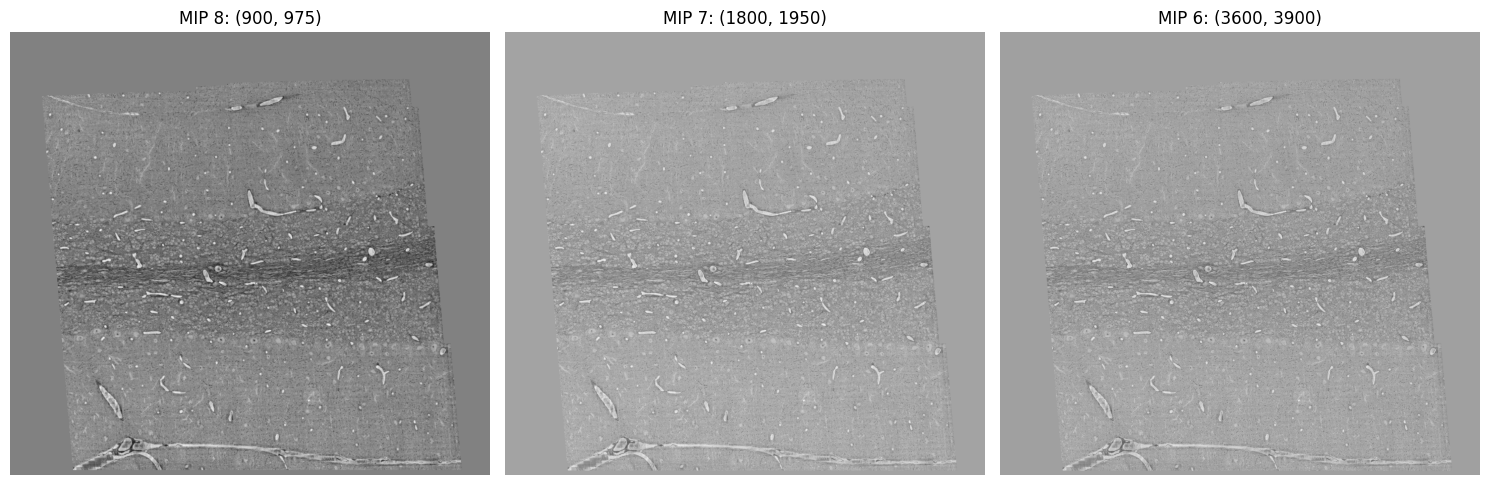

MIP 8 resolution: [1024 1024   40] shape: (975, 900, 1200, 1) chunk: [512 512   1]
MIP 7 resolution: [512 512  40] shape: (1950, 1800, 1200, 1) chunk: [512 512   1]
MIP 6 resolution: [256 256  40] shape: (3900, 3600, 1200, 1) chunk: [512 512   1]
MIP 5 resolution: [128 128  40] shape: (7800, 7200, 1200, 1) chunk: [512 512   1]


In [23]:
import numpy as np
import matplotlib.pyplot as plt
from cloudvolume import CloudVolume

path = (
    "file:///volume_4/research/seongbong/"
    "align/Final_cerebellum_alignment/render_sift_new_masked_normalized"
)

z = 325

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, mip in zip(axes, [8, 7, 6]):

    cv = CloudVolume(
        path,
        mip=mip,
        progress=False,
        fill_missing=False
    )

    b = cv.bounds

    img = np.asarray(
        cv[
            b.minpt.x:b.maxpt.x,
            b.minpt.y:b.maxpt.y,
            z:z+1
        ]
    )[:, :, 0, 0].T

    ax.imshow(img, cmap="gray")
    ax.set_title(f"MIP {mip}: {img.shape}")
    ax.axis("off")

plt.tight_layout()
plt.show()

for mip in [8, 7, 6, 5]:

    cv = CloudVolume(path, mip=mip)

    print(
        f"MIP {mip}",
        "resolution:", cv.resolution,
        "shape:", cv.shape,
        "chunk:", cv.chunk_size
    )

In [27]:
import json
from pathlib import Path

path = Path(
    "/volume_4/research/seongbong/"
    "align/Final_cerebellum_alignment/render_sift_new_masked_normalized"
)


with open(path / "info") as f:
    info = json.load(f)

for i, scale in enumerate(info["scales"]):
    print(
        f"MIP {i}:",
        "key =", scale["key"],
        "resolution =", scale["resolution"],
        "size =", scale["size"],
        "chunk_sizes =", scale["chunk_sizes"]
    )

MIP 0: key = 4_4_40 resolution = [4, 4, 40] size = [249600, 230400, 1200] chunk_sizes = [[512, 512, 1]]
MIP 1: key = 8_8_40 resolution = [8, 8, 40] size = [124800, 115200, 1200] chunk_sizes = [[512, 512, 1]]
MIP 2: key = 16_16_40 resolution = [16, 16, 40] size = [62400, 57600, 1200] chunk_sizes = [[512, 512, 1]]
MIP 3: key = 32_32_40 resolution = [32, 32, 40] size = [31200, 28800, 1200] chunk_sizes = [[512, 512, 1]]
MIP 4: key = 64_64_40 resolution = [64, 64, 40] size = [15600, 14400, 1200] chunk_sizes = [[512, 512, 1]]
MIP 5: key = 128_128_40 resolution = [128, 128, 40] size = [7800, 7200, 1200] chunk_sizes = [[512, 512, 1]]
MIP 6: key = 256_256_40 resolution = [256, 256, 40] size = [3900, 3600, 1200] chunk_sizes = [[512, 512, 1]]
MIP 7: key = 512_512_40 resolution = [512, 512, 40] size = [1950, 1800, 1200] chunk_sizes = [[512, 512, 1]]
MIP 8: key = 1024_1024_40 resolution = [1024, 1024, 40] size = [975, 900, 1200] chunk_sizes = [[512, 512, 1]]
MIP 9: key = 2048_2048_40 resolution = [

In [28]:
import requests
import numpy as np

url = (
    "http://localhost:8080/"
    "render_sift_new_masked_normalized/"
    "256_256_40/0-512_0-512_325-326"
)

r = requests.get(url)
r.raise_for_status()

print("HTTP:", r.status_code)
print("Bytes:", len(r.content))

arr = np.frombuffer(r.content, dtype="<f4")

print("Pixel count:", arr.size)
print("Expected:", 512 * 512)
print("Min:", arr.min())
print("Max:", arr.max())
print("Mean:", arr.mean())
print("Std:", arr.std())

HTTP: 200
Bytes: 1048576
Pixel count: 262144
Expected: 262144
Min: 0.0
Max: 1.1256143
Mean: 1.8217108e-05
Std: 0.0039824834


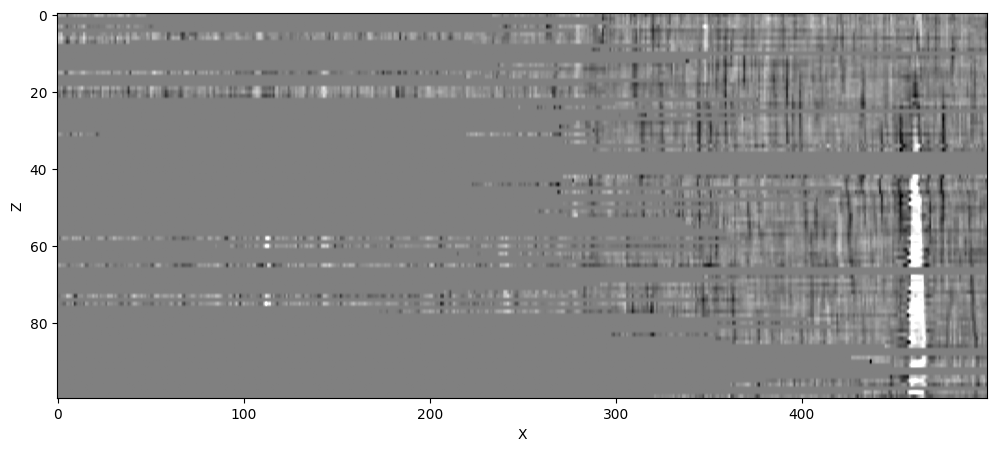

In [29]:
from cloudvolume import CloudVolume
import numpy as np
import matplotlib.pyplot as plt

path = (
    "file:///volume_4/research/seongbong/align/"
    "Final_cerebellum_alignment/"
    "render_sift_new_masked_normalized"
)

cv = CloudVolume(path, mip=8, progress=False)

# XZ 단면: Y를 고정
data = np.asarray(
    cv[100:600, 100:101, 300:400]
)

xz = data[:, 0, :, 0].T

plt.figure(figsize=(12, 5))
plt.imshow(
    xz,
    cmap="gray",
    vmin=-3,
    vmax=3,
    aspect="auto"
)
plt.xlabel("X")
plt.ylabel("Z")
plt.show()